# Análisis de los experimentos del gemelo ACO

Este notebook lee los resultados de los experimentos en lote (`../experimentos/datos/`) y responde dos preguntas:

1. **¿Qué aporta cada modo de la madre** (ausente, pista de baile, rescate, difusión) en el mundo L del plano y en mundos con obstáculos aleatorios?
2. **¿Reduce el rescate la varianza del tiempo de convergencia?** Es la hipótesis de `referencia/resumen.pdf`.

**Para regenerar los datos** (desde `gemelo/`, con el Python del entorno `aco-gemelo`):

```
python -X utf8 -m aco_gemelo experimentos --plan experimentos/modos.yaml
python -X utf8 -m aco_gemelo experimentos --plan experimentos/rescate.yaml
```

Las conclusiones del final **se calculan a partir de los datos**: si se vuelven a correr los experimentos, se actualizan solas.
Definiciones: una colonia **converge** si todas las agentes se asientan en la meta y la verificadora llega siguiendo solo el rastro (decisión G1).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact, levene, mannwhitneyu

DATOS = Path("..") / "experimentos" / "datos"
FIGURAS = Path("figuras")
FIGURAS.mkdir(exist_ok=True)

# Colores del plano de ensayo (bosquejo/)
COLOR = {"ausente": "#94a3b8", "pista_de_baile": "#15803d", "rescate": "#d97706", "difusion": "#2563eb"}
MODOS = ["ausente", "pista_de_baile", "rescate", "difusion"]
NOMBRE = {"ausente": "Sin madre", "pista_de_baile": "Pista de baile", "rescate": "Rescate (umbral 0,5)",
          "difusion": "Difusión"}
ESCENARIOS = {"L": "Mundo L (plano)", "aleatorio": "Mundo aleatorio"}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})


def leer(plan):
    """Todos los ensayos de un plan (una fila por semilla) y su resumen."""
    carpeta = DATOS / plan
    ensayos = pd.concat([pd.read_csv(p) for p in sorted(carpeta.glob("*.csv")) if p.name != "resumen.csv"],
                        ignore_index=True)
    return ensayos, pd.read_csv(carpeta / "resumen.csv")


modos, resumen_modos = leer("modos")
rescate, resumen_rescate = leer("rescate")
print(f"modos: {len(modos)} ensayos · rescate: {len(rescate)} ensayos")

modos: 240 ensayos · rescate: 240 ensayos


## 1. Los modos de la madre

Resumen por condición (30 semillas cada una; intervalos de confianza de Wilson al 95 %).

In [2]:
columnas = ["escenario", "modo", "verificadas", "verificadas_ic95_bajo", "verificadas_ic95_alto",
            "ticks_media", "ticks_varianza", "razon_media", "bytes_agente_madre_media", "bytes_madre_agente_media"]
tabla = resumen_modos[columnas].copy()
tabla["bytes_madre"] = tabla.pop("bytes_agente_madre_media") + tabla.pop("bytes_madre_agente_media")
tabla.round(2)

,escenario,modo,verificadas,verificadas_ic95_bajo,verificadas_ic95_alto,ticks_media,ticks_varianza,razon_media,bytes_madre
0,L,ausente,21,0.52,0.83,465.47,20369.32,1.44,0.00
1,L,pista_de_baile,24,0.63,0.90,433.30,13984.41,1.67,4664.97
2,L,rescate,21,0.52,0.83,465.47,20369.32,1.44,4881.33
3,L,difusion,25,0.66,0.93,441.30,27752.41,1.58,6324.80
4,aleatorio,ausente,18,0.42,0.75,427.57,18925.18,1.28,0.00
5,aleatorio,pista_de_baile,25,0.66,0.93,390.33,12108.16,1.42,4225.87
6,aleatorio,rescate,18,0.42,0.75,427.57,18925.18,1.28,4484.63
7,aleatorio,difusion,25,0.66,0.93,417.23,25092.71,1.26,5935.30


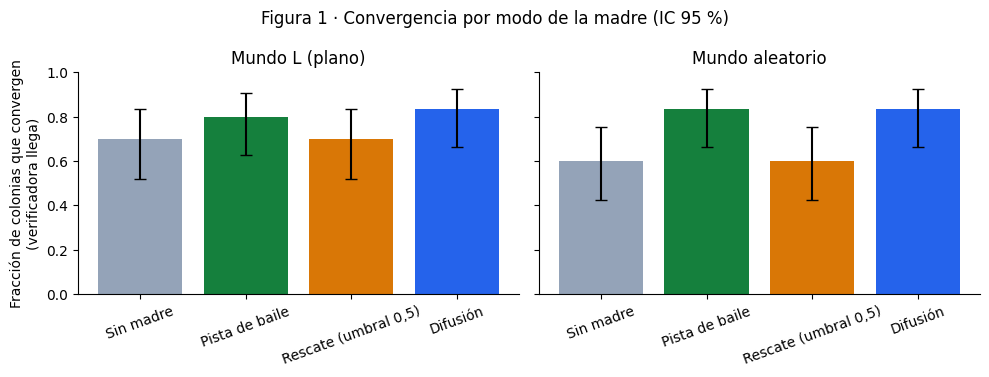

In [3]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for eje, (escenario, titulo) in zip(ejes, ESCENARIOS.items()):
    filas = resumen_modos.set_index("escenario").loc[escenario].set_index("modo").loc[MODOS]
    tasa = filas["verificadas_tasa"]
    error = [tasa - filas["verificadas_ic95_bajo"], filas["verificadas_ic95_alto"] - tasa]
    eje.bar([NOMBRE[m] for m in MODOS], tasa, yerr=error, capsize=4, color=[COLOR[m] for m in MODOS])
    eje.set_title(titulo)
    eje.set_ylim(0, 1)
    eje.tick_params(axis="x", rotation=20)
ejes[0].set_ylabel("Fracción de colonias que convergen\n(verificadora llega)")
fig.suptitle("Figura 1 · Convergencia por modo de la madre (IC 95 %)")
fig.tight_layout()
fig.savefig(FIGURAS / "f1_convergencia_por_modo.png")

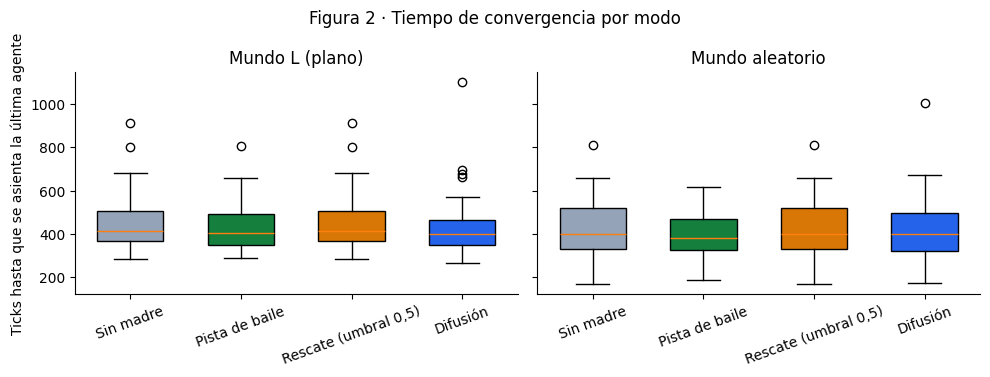

In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for eje, (escenario, titulo) in zip(ejes, ESCENARIOS.items()):
    datos = [modos[(modos.escenario == escenario) & (modos.modo == m)]["ticks_asentadas"].dropna() for m in MODOS]
    caja = eje.boxplot(datos, patch_artist=True, widths=0.6)
    for parche, m in zip(caja["boxes"], MODOS):
        parche.set_facecolor(COLOR[m])
    eje.set_xticks(range(1, 5), [NOMBRE[m] for m in MODOS], rotation=20)
    eje.set_title(titulo)
ejes[0].set_ylabel("Ticks hasta que se asienta la última agente")
fig.suptitle("Figura 2 · Tiempo de convergencia por modo")
fig.tight_layout()
fig.savefig(FIGURAS / "f2_tiempo_por_modo.png")

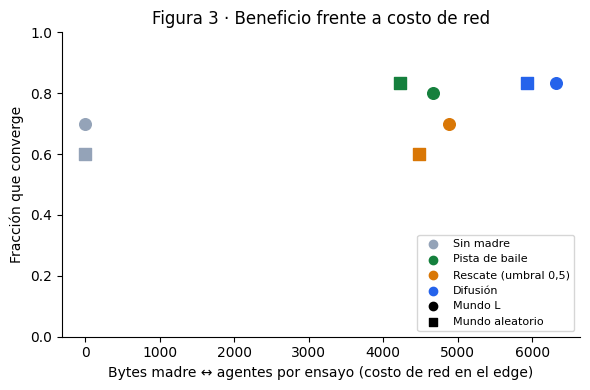

In [5]:
fig, eje = plt.subplots(figsize=(6, 4))
for escenario, marca in (("L", "o"), ("aleatorio", "s")):
    filas = resumen_modos[resumen_modos.escenario == escenario]
    for _, f in filas.iterrows():
        eje.scatter(f.bytes_agente_madre_media + f.bytes_madre_agente_media, f.verificadas_tasa,
                    color=COLOR[f.modo], marker=marca, s=70)
for m in MODOS:
    eje.scatter([], [], color=COLOR[m], label=NOMBRE[m])
eje.scatter([], [], color="k", marker="o", label="Mundo L")
eje.scatter([], [], color="k", marker="s", label="Mundo aleatorio")
eje.set_xlabel("Bytes madre ↔ agentes por ensayo (costo de red en el edge)")
eje.set_ylabel("Fracción que converge")
eje.set_ylim(0, 1)
eje.legend(fontsize=8, loc="lower right")
eje.set_title("Figura 3 · Beneficio frente a costo de red")
fig.tight_layout()
fig.savefig(FIGURAS / "f3_costo_de_red.png")

## 2. ¿Reduce el rescate la varianza del tiempo de convergencia?

Con el umbral por defecto (0,5) el rescate nunca se dispara: sus resultados son idénticos a los de "sin madre".
El plan `rescate` barre el umbral (rezagada = experiencia menor que esa fracción del promedio de la colonia).

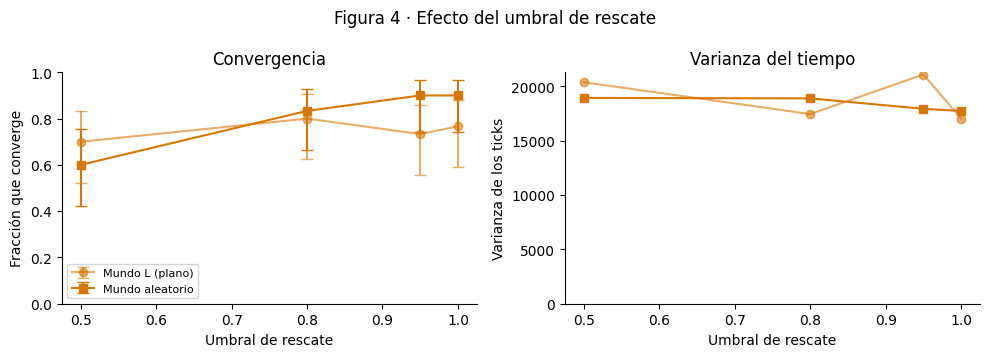

In [6]:
fig, (izq, der) = plt.subplots(1, 2, figsize=(10, 3.6))
for escenario, marca in (("L", "o-"), ("aleatorio", "s-")):
    filas = resumen_rescate[resumen_rescate.escenario == escenario].sort_values("umbral_rescate")
    tasa = filas["verificadas_tasa"]
    izq.errorbar(filas["umbral_rescate"], tasa, fmt=marca, capsize=4, color=COLOR["rescate"],
                 yerr=[tasa - filas["verificadas_ic95_bajo"], filas["verificadas_ic95_alto"] - tasa],
                 label=ESCENARIOS[escenario], alpha=0.6 if escenario == "L" else 1)
    der.plot(filas["umbral_rescate"], filas["ticks_varianza"], marca, color=COLOR["rescate"],
             label=ESCENARIOS[escenario], alpha=0.6 if escenario == "L" else 1)
izq.set(xlabel="Umbral de rescate", ylabel="Fracción que converge", ylim=(0, 1), title="Convergencia")
der.set(xlabel="Umbral de rescate", ylabel="Varianza de los ticks", title="Varianza del tiempo")
der.set_ylim(bottom=0)
izq.legend(fontsize=8)
fig.suptitle("Figura 4 · Efecto del umbral de rescate")
fig.tight_layout()
fig.savefig(FIGURAS / "f4_umbral_de_rescate.png")

### Pruebas estadísticas

> **Advertencia de método:** estas pruebas se fijaron **después** de una mirada exploratoria a los mismos datos (F-018, que usó Levene centrada en la media). Por eso son **exploratorias, no confirmatorias**: para confirmar un efecto haría falta un experimento nuevo, con más semillas y las pruebas declaradas antes.

Para cada mundo se compara **sin madre** (que equivale a "sin rescate") con el **rescate a umbral 0,8, 0,95 y 1,0**:

- **Varianza del tiempo:** prueba de Brown-Forsythe (Levene centrada en la mediana), porque los tiempos no son normales.
- **Tiempo típico:** Mann-Whitney U, bilateral.
- **Tasa de convergencia:** prueba exacta de Fisher, bilateral.
- Como son 6 comparaciones por prueba, se usa **corrección de Bonferroni** (α = 0,05 / 6). La hipótesis de `resumen.pdf` se considera apoyada si la varianza con rescate es **menor** y la diferencia es significativa tras corregir.

In [7]:
filas = []
for escenario in ESCENARIOS:
    sin = modos[(modos.escenario == escenario) & (modos.modo == "ausente")]
    for umbral in (0.8, 0.95, 1.0):
        con = rescate[(rescate.escenario == escenario) & np.isclose(rescate.umbral_rescate, umbral)]
        t_sin, t_con = sin["ticks_asentadas"].dropna(), con["ticks_asentadas"].dropna()
        v_sin, v_con = int(sin["verificada"].sum()), int(con["verificada"].sum())
        filas.append({
            "escenario": escenario, "umbral": umbral,
            "varianza_sin": round(t_sin.var(ddof=0)), "varianza_con": round(t_con.var(ddof=0)),
            "p_varianza": levene(t_sin, t_con, center="median").pvalue,
            "p_tiempo": mannwhitneyu(t_sin, t_con).pvalue,
            "converge_sin": f"{v_sin}/{len(sin)}", "converge_con": f"{v_con}/{len(con)}",
            "p_convergencia": fisher_exact([[v_con, len(con) - v_con], [v_sin, len(sin) - v_sin]]).pvalue,
        })
pruebas = pd.DataFrame(filas)
for columna in ("p_varianza", "p_tiempo", "p_convergencia"):
    pruebas[columna + "_bonferroni"] = (pruebas[columna] * len(pruebas)).clip(upper=1)
pruebas.round(3)

,escenario,umbral,varianza_sin,varianza_con,p_varianza,p_tiempo,converge_sin,converge_con,p_convergencia,p_varianza_bonferroni,p_tiempo_bonferroni,p_convergencia_bonferroni
0,L,0.80,20369,17442,0.914,0.344,21/30,24/30,0.552,1.0,1.000,1.000
1,L,0.95,20369,21076,0.905,0.158,21/30,22/30,1.000,1.0,0.948,1.000
2,L,1.00,20369,17030,0.911,0.167,21/30,23/30,0.771,1.0,1.000,1.000
3,aleatorio,0.80,18925,18884,0.857,0.325,18/30,25/30,0.084,1.0,1.000,0.504
4,aleatorio,0.95,18925,17925,0.843,0.387,18/30,27/30,0.015,1.0,1.000,0.092
5,aleatorio,1.00,18925,17725,0.807,0.395,18/30,27/30,0.015,1.0,1.000,0.092


## 3. Conclusiones (calculadas a partir de los datos)

In [8]:
ALFA = 0.05
apoyos = pruebas[(pruebas.varianza_con < pruebas.varianza_sin) & (pruebas.p_varianza_bonferroni < ALFA)]
mejoras = pruebas[pruebas.p_convergencia_bonferroni < ALFA]
mejor = pruebas.loc[pruebas.p_convergencia.idxmin()]

print("Modos de la madre (Figura 1):")
for escenario in ESCENARIOS:
    filas = resumen_modos[resumen_modos.escenario == escenario].set_index("modo")
    texto = ", ".join(f"{NOMBRE[m].split(' (')[0].lower()} {int(filas.loc[m, 'verificadas'])}/30" for m in MODOS)
    print(f"  - {ESCENARIOS[escenario]}: {texto}.")
print()
print("Hipótesis de resumen.pdf (el rescate reduce la varianza del tiempo):")
if len(apoyos):
    print(f"  APOYADA en {len(apoyos)} de {len(pruebas)} comparaciones tras corregir por Bonferroni.")
else:
    print(f"  NO apoyada: en ninguna de las {len(pruebas)} comparaciones la varianza con rescate es menor "
          f"de forma significativa tras corregir (p de Brown-Forsythe corregido mínimo = "
          f"{pruebas.p_varianza_bonferroni.min():.2f}).")
print()
print("Convergencia con rescate frente a sin madre:")
if len(mejoras):
    print(f"  Mejora significativa tras corregir en {len(mejoras)} comparaciones.")
else:
    print(f"  Ninguna diferencia significativa tras corregir. La más fuerte: {ESCENARIOS[mejor.escenario]}, "
          f"umbral {mejor.umbral}: {mejor.converge_con} frente a {mejor.converge_sin} "
          f"(p = {mejor.p_convergencia:.3f} sin corregir; {mejor.p_convergencia_bonferroni:.2f} corregido).")
    print("  Para confirmarla o descartarla harían falta más semillas (≈ 100 por condición).")

Modos de la madre (Figura 1):
  - Mundo L (plano): sin madre 21/30, pista de baile 24/30, rescate 21/30, difusión 25/30.
  - Mundo aleatorio: sin madre 18/30, pista de baile 25/30, rescate 18/30, difusión 25/30.

Hipótesis de resumen.pdf (el rescate reduce la varianza del tiempo):
  NO apoyada: en ninguna de las 6 comparaciones la varianza con rescate es menor de forma significativa tras corregir (p de Brown-Forsythe corregido mínimo = 1.00).

Convergencia con rescate frente a sin madre:
  Ninguna diferencia significativa tras corregir. La más fuerte: Mundo aleatorio, umbral 0.95: 27/30 frente a 18/30 (p = 0.015 sin corregir; 0.09 corregido).
  Para confirmarla o descartarla harían falta más semillas (≈ 100 por condición).
